# 01 - EDA: SHAI Music Genre Classification
Khám phá dữ liệu: phân phối nhãn, missing values, đơn vị duration, tương quan feature.

In [1]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns
from pathlib import Path
D=Path('../data'); OUT=Path('../outputs/figures'); OUT.mkdir(exist_ok=True)
train=pd.read_csv(D/'train.csv'); test=pd.read_csv(D/'test.csv')
print(train.shape, test.shape); train.head()

(14396, 18) (3600, 17)


,Id,Artist Name,Track Name,Popularity,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_in min/ms,time_signature,Class
0,1,Marina Maximilian,Not Afraid,37.0,0.334,0.536,9.0,-6.649,0,0.0381,0.378000,NaN,0.106,0.235,152.429,204947.0,4,9
1,2,The Black Keys,Howlin' for You,67.0,0.725,0.747,11.0,-5.545,1,0.0876,0.027200,0.0468,0.104,0.380,132.921,191956.0,4,6
2,3,Royal & the Serpent,phuck u,NaN,0.584,0.804,7.0,-6.094,1,0.0619,0.000968,0.6350,0.284,0.635,159.953,161037.0,4,10
3,4,Detroit Blues Band,Missing You,12.0,0.515,0.308,NaN,-14.711,1,0.0312,0.907000,0.0213,0.300,0.501,172.472,298093.0,3,2
4,5,Coast Contra,My Lady,48.0,0.565,0.777,6.0,-5.096,0,0.2490,0.183000,NaN,0.211,0.619,88.311,254145.0,4,5


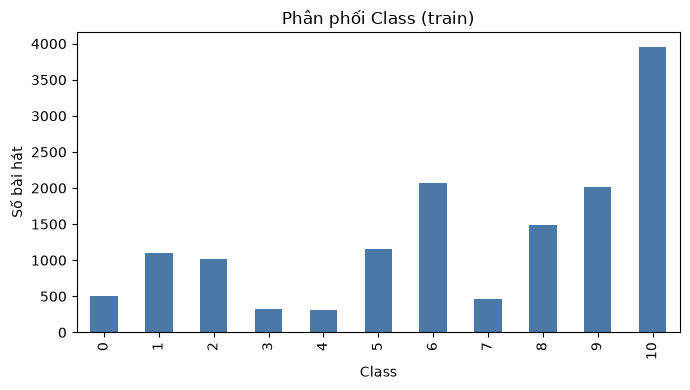

In [ ]:
ax=train.Class.value_counts().sort_index().plot(kind='bar',figsize=(7,4),color='#4C78A8')
ax.set_title('Phân phối Class (train)'); ax.set_xlabel('Class'); ax.set_ylabel('Số bài hát')
plt.tight_layout(); plt.savefig(OUT/'eda_class_dist.png',dpi=150); plt.show()

Popularity           2.3
key                 11.2
instrumentalness    24.6


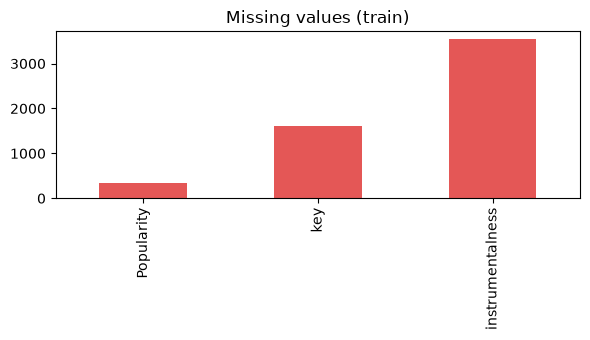

In [ ]:
miss=train.isna().sum(); miss=miss[miss>0]; print((miss/len(train)*100).round(1).to_string())
ax=miss.plot(kind='bar',figsize=(6,3.5),color='#E45756'); ax.set_title('Missing values (train)')
plt.tight_layout(); plt.savefig(OUT/'eda_missing.png',dpi=150); plt.show()

In [ ]:
d=train['duration_in min/ms']; print('Số dòng < 100 (nhiều khả năng là phút):',(d<100).sum()); print(d[d<100].describe())

Số dòng < 100 (nhiều khả năng là phút): 2075
count    2075.000000
mean        4.062061
std         1.628287
min         0.501650
25%         3.115458
50%         3.733317
75%         4.597333
max        29.886000
Name: duration_in min/ms, dtype: float64


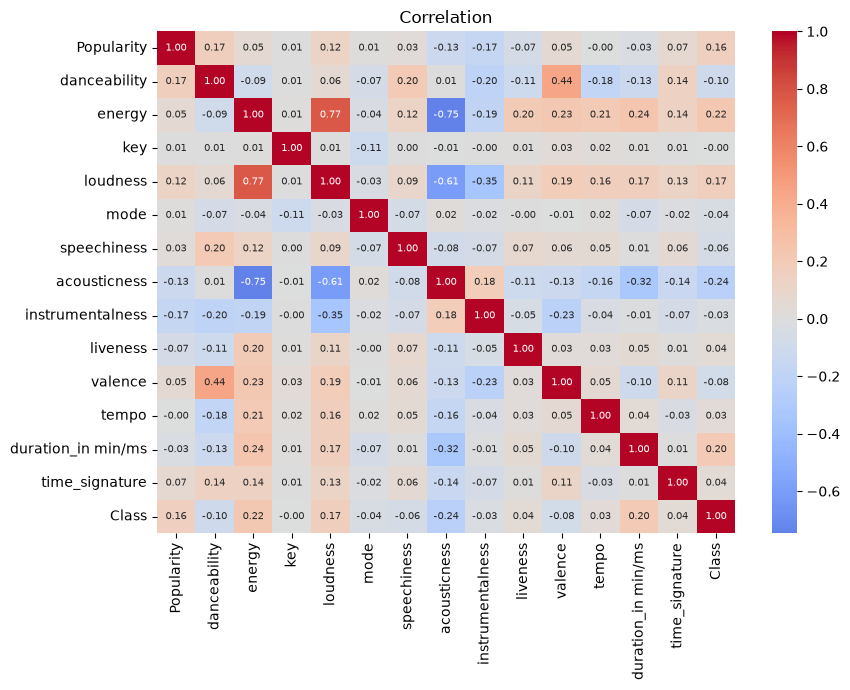

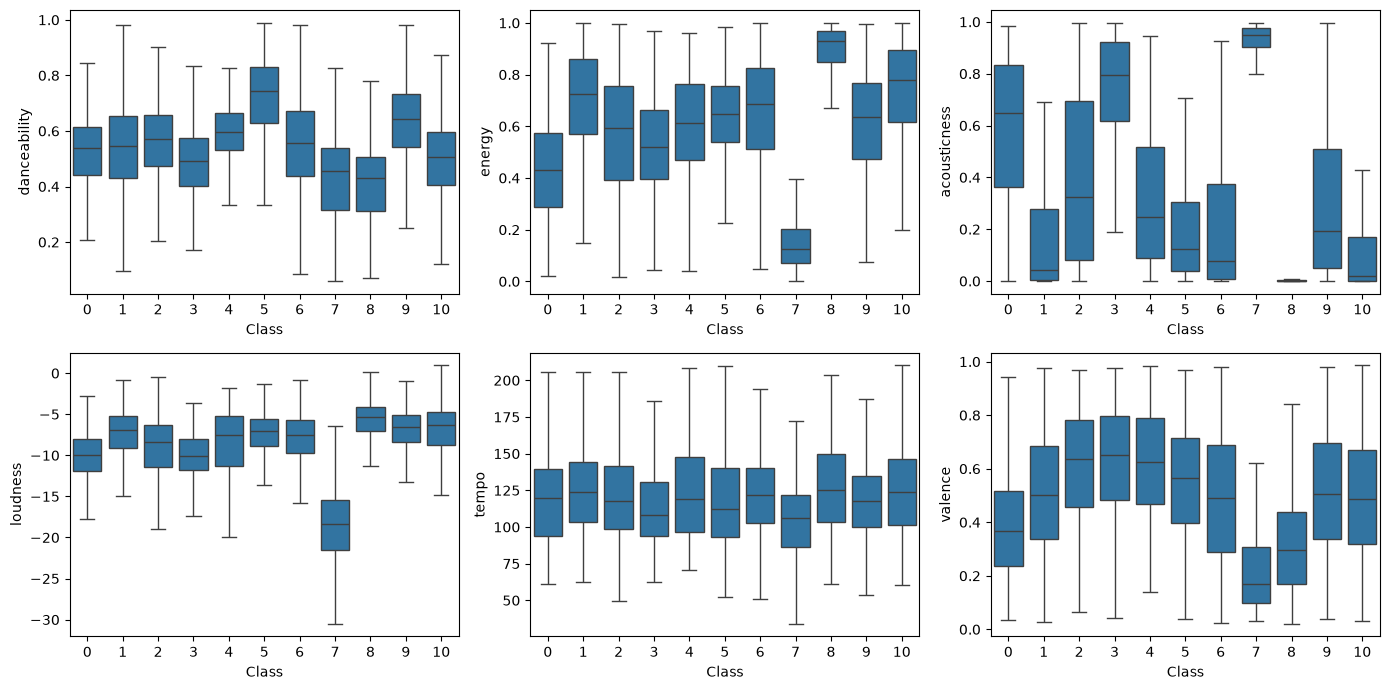

In [ ]:
num=train.select_dtypes('number').drop(columns=['Id'])
plt.figure(figsize=(9,7)); sns.heatmap(num.corr(),cmap='coolwarm',center=0,annot=True,fmt='.2f',annot_kws={'size':7})
plt.title('Correlation'); plt.tight_layout(); plt.savefig(OUT/'eda_corr.png',dpi=150); plt.show()
fig,axs=plt.subplots(2,3,figsize=(14,7))
for ax,c in zip(axs.ravel(),['danceability','energy','acousticness','loudness','tempo','valence']):
    sns.boxplot(data=train,x='Class',y=c,ax=ax,showfliers=False)
plt.tight_layout(); plt.savefig(OUT/'eda_features_by_class.png',dpi=150); plt.show()

In [ ]:
print('Test có nghệ sĩ xuất hiện trong train: %.1f%%'%(test['Artist Name'].isin(train['Artist Name']).mean()*100))

Test có nghệ sĩ xuất hiện trong train: 63.8%
